# 07_02 — Llama 3.1 Summary Quality Evaluation

Evaluates Llama 3.1-generated pros/cons without reference summaries using 3 quality checks:

| # | Metric | Method | What it answers |
|---|---|---|---|
| 1 | **Relevance** | BGE-M3 cosine similarity | Does the summary match the source reviews? |
| 2 | **Coverage** | ROUGE-1 Recall | How much of the source content is captured? |
| 3 | **Conciseness** | Length ratio | Is it actually shorter than the source? |

In [1]:
import os
import glob
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from rouge_score import rouge_scorer
import sys
sys.path.append(os.path.abspath('..'))
from sentence_transformers import util
from utils.embeddings import get_embedder
from tqdm.auto import tqdm

DATA_DIR = os.path.abspath('../data/processed/sentiment')
print('Libraries loaded.')

W1105 21:24:13.502000 22913 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Libraries loaded.


## 1. Load Summaries & Rebuild Source Corpus

In [2]:
# load the 3 completed summary parquets
sum_files = [
    os.path.join(DATA_DIR, 'apparel_summaries.parquet'),
    os.path.join(DATA_DIR, 'beauty_summaries.parquet'),
    os.path.join(DATA_DIR, 'books_summaries.parquet'),
    os.path.join(DATA_DIR, "mobile_summaries.parquet"),
    os.path.join(DATA_DIR, "outdoors_summaries.parquet"),
    os.path.join(DATA_DIR, "furniture_summaries.parquet")
]
summary_df = pd.concat([pd.read_parquet(f) for f in sum_files], ignore_index=True)
summary_df = summary_df.dropna(subset=['pros', 'cons']).reset_index(drop=True)
print(f'Summaries : {len(summary_df):,} products across {summary_df["product_category"].nunique()} categories')

# rebuild the exact corpus fed into Llama 3.1 (same params as notebook 04)
MAX_REVIEWS_PER_SIDE = 10
MAX_CHARS_PER_REVIEW = 500

parts = glob.glob(os.path.join(DATA_DIR, 'sentiment_scored', 'part-*.parquet'))
scored_df = pd.concat(
    [pd.read_parquet(p, columns=['product_id', 'review', 'llama_label']) for p in parts],
    ignore_index=True,
)
scored_df['llama_label'] = scored_df['llama_label'].str.lower().str.strip()
scored_df = scored_df[scored_df['product_id'].isin(summary_df['product_id'])]

def build_corpus(reviews):
    return ' '.join(r[:MAX_CHARS_PER_REVIEW] for r in reviews.dropna().head(MAX_REVIEWS_PER_SIDE))

pos_source = scored_df[scored_df['llama_label'] == 'positive'].groupby('product_id')['review'].apply(build_corpus).rename('pos_source')
neg_source = scored_df[scored_df['llama_label'] == 'negative'].groupby('product_id')['review'].apply(build_corpus).rename('neg_source')

eval_df = summary_df.merge(pos_source, on='product_id', how='left').merge(neg_source, on='product_id', how='left')
eval_df['pos_source'] = eval_df['pos_source'].fillna('')
eval_df['neg_source'] = eval_df['neg_source'].fillna('')
print(f'Evaluation set ready: {len(eval_df):,} products')

Summaries : 27 products across 6 categories
Evaluation set ready: 27 products


## 2. Relevance — BGE-M3 Cosine Similarity

Encodes summary and source reviews with BGE-M3 and measures cosine similarity.
**Score 0–1, higher = summary is more semantically aligned with source.**

In [3]:
sbert = get_embedder()
print('BGE-M3 loaded.')

pros_sim, cons_sim = [], []
for _, row in tqdm(eval_df.iterrows(), total=len(eval_df), desc='Relevance'):
    if row['pos_source']:
        pros_sim.append(float(util.cos_sim(
            sbert.encode(row['pos_source'], convert_to_tensor=True),
            sbert.encode(row['pros'],       convert_to_tensor=True)
        )))
    else:
        pros_sim.append(np.nan)
    if row['neg_source']:
        cons_sim.append(float(util.cos_sim(
            sbert.encode(row['neg_source'], convert_to_tensor=True),
            sbert.encode(row['cons'],       convert_to_tensor=True)
        )))
    else:
        cons_sim.append(np.nan)

eval_df['pros_relevance'] = pros_sim
eval_df['cons_relevance'] = cons_sim

print(f"\nRelevance (BGE-M3 cosine similarity):")
print(f"  Pros — mean={eval_df['pros_relevance'].mean():.3f}  median={eval_df['pros_relevance'].median():.3f}")
print(f"  Cons — mean={eval_df['cons_relevance'].mean():.3f}  median={eval_df['cons_relevance'].median():.3f}")

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 391/391 [00:00<00:00, 54087.03it/s]

BGE-M3 loaded.


Relevance:   0%|          | 0/27 [00:00<?, ?it/s]

Relevance:   4%|▎         | 1/27 [00:02<01:02,  2.40s/it]

Relevance:   7%|▋         | 2/27 [00:02<00:30,  1.23s/it]

... (23 outputs left out)

Relevance:  96%|█████████▋| 26/27 [00:12<00:00,  1.85it/s]

Relevance: 100%|██████████| 27/27 [00:13<00:00,  1.78it/s]

Relevance: 100%|██████████| 27/27 [00:13<00:00,  2.00it/s]


Relevance (BGE-M3 cosine similarity):
  Pros — mean=0.791  median=0.797
  Cons — mean=0.749  median=0.761


## 3. Coverage — ROUGE-1 Recall

Measures what fraction of source review words appear in the summary.
**Higher recall = more source content is captured.**

In [4]:
scorer = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rougeL'], use_stemmer=True)

pros_r1, pros_r2, pros_rl = [], [], []
cons_r1, cons_r2, cons_rl = [], [], []

for _, row in tqdm(eval_df.iterrows(), total=len(eval_df), desc='Coverage'):
    if row['pos_source']:
        s = scorer.score(row['pos_source'], row['pros'])
        pros_r1.append(s['rouge1'].recall)
        pros_r2.append(s['rouge2'].recall)
        pros_rl.append(s['rougeL'].recall)
    else:
        pros_r1.append(np.nan); pros_r2.append(np.nan); pros_rl.append(np.nan)
    if row['neg_source']:
        s = scorer.score(row['neg_source'], row['cons'])
        cons_r1.append(s['rouge1'].recall)
        cons_r2.append(s['rouge2'].recall)
        cons_rl.append(s['rougeL'].recall)
    else:
        cons_r1.append(np.nan); cons_r2.append(np.nan); cons_rl.append(np.nan)

eval_df['pros_rouge1'] = pros_r1
eval_df['pros_rouge2'] = pros_r2
eval_df['pros_rougeL'] = pros_rl
eval_df['cons_rouge1'] = cons_r1
eval_df['cons_rouge2'] = cons_r2
eval_df['cons_rougeL'] = cons_rl

print('Coverage (ROUGE Recall):')
for side in ['pros', 'cons']:
    print(f'  {side.upper()}')
    for m in ['rouge1', 'rouge2', 'rougeL']:
        col = f'{side}_{m}'
        print(f'    {m}: mean={eval_df[col].mean():.3f}  median={eval_df[col].median():.3f}')

Coverage:   0%|          | 0/27 [00:00<?, ?it/s]

Coverage:  19%|█▊        | 5/27 [00:00<00:00, 43.17it/s]

Coverage:  37%|███▋      | 10/27 [00:02<00:04,  3.78it/s]

Coverage:  85%|████████▌ | 23/27 [00:02<00:00, 11.32it/s]

Coverage: 100%|██████████| 27/27 [00:02<00:00, 11.16it/s]

Coverage (ROUGE Recall):
  PROS
    rouge1: mean=0.142  median=0.110
    rouge2: mean=0.040  median=0.030
    rougeL: mean=0.084  median=0.071
  CONS
    rouge1: mean=0.196  median=0.140
    rouge2: mean=0.076  median=0.037
    rougeL: mean=0.140  median=0.078


## 4. Conciseness — Length Ratio

`summary length / source length` — lower means more compressed.
**A good summary should be well below 0.5.**

In [5]:
eval_df['pros_conciseness'] = eval_df.apply(
    lambda r: len(r['pros']) / len(r['pos_source']) if len(r['pos_source']) > 0 else np.nan, axis=1
)
eval_df['cons_conciseness'] = eval_df.apply(
    lambda r: len(r['cons']) / len(r['neg_source']) if len(r['neg_source']) > 0 else np.nan, axis=1
)

print('Conciseness (length ratio — lower = more compressed):')
print(f"  Pros — mean={eval_df['pros_conciseness'].mean():.3f}  median={eval_df['pros_conciseness'].median():.3f}")
print(f"  Cons — mean={eval_df['cons_conciseness'].mean():.3f}  median={eval_df['cons_conciseness'].median():.3f}")

Conciseness (length ratio — lower = more compressed):
  Pros — mean=0.260  median=0.189
  Cons — mean=1.008  median=0.286


## 5. Visualisation

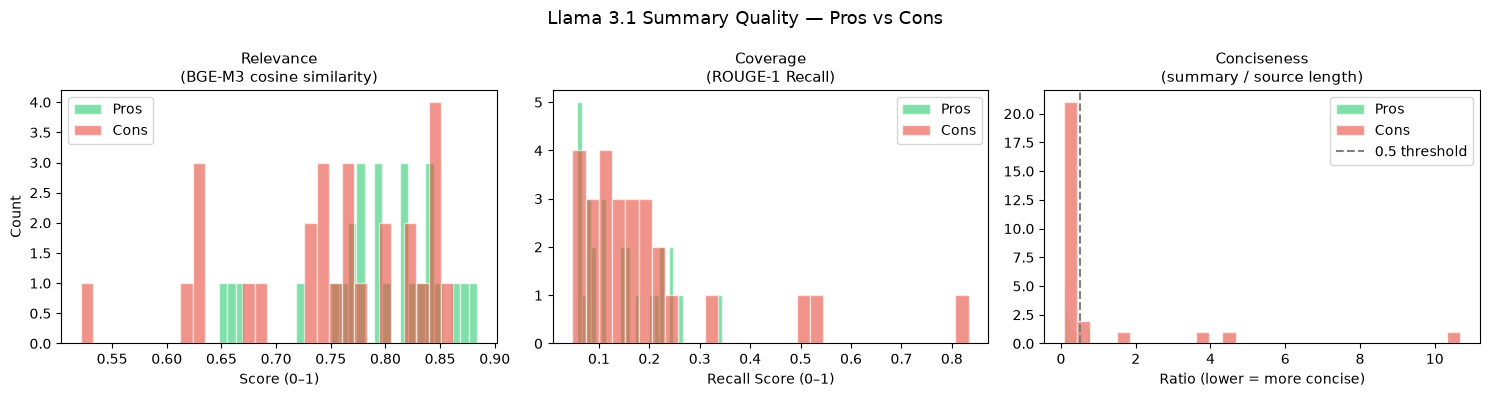

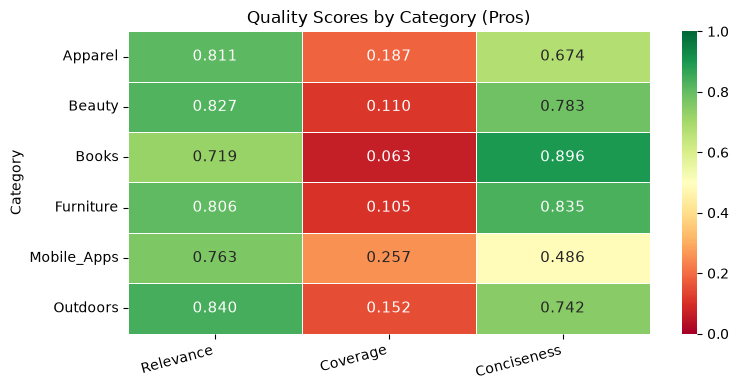

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# relevance
for side, color in [('pros', '#2ecc71'), ('cons', '#e74c3c')]:
    axes[0].hist(eval_df[f'{side}_relevance'].dropna(), bins=30, alpha=0.6, color=color, label=side.capitalize(), edgecolor='white')
axes[0].set_title('Relevance\n(BGE-M3 cosine similarity)', fontsize=11)
axes[0].set_xlabel('Score (0–1)')
axes[0].set_ylabel('Count')
axes[0].legend()

# coverage
for side, color in [('pros', '#2ecc71'), ('cons', '#e74c3c')]:
    axes[1].hist(eval_df[f'{side}_rouge1'].dropna(), bins=30, alpha=0.6, color=color, label=side.capitalize(), edgecolor='white')
axes[1].set_title('Coverage\n(ROUGE-1 Recall)', fontsize=11)
axes[1].set_xlabel('Recall Score (0–1)')
axes[1].legend()

# conciseness
for side, color in [('pros', '#2ecc71'), ('cons', '#e74c3c')]:
    axes[2].hist(eval_df[f'{side}_conciseness'].dropna(), bins=30, alpha=0.6, color=color, label=side.capitalize(), edgecolor='white')
axes[2].axvline(0.5, color='gray', linestyle='--', label='0.5 threshold')
axes[2].set_title('Conciseness\n(summary / source length)', fontsize=11)
axes[2].set_xlabel('Ratio (lower = more concise)')
axes[2].legend()

plt.suptitle('Llama 3.1 Summary Quality — Pros vs Cons', fontsize=13)
plt.tight_layout()
plt.show()

# per-category heatmap
cat_rows = []
for cat, grp in eval_df.groupby('product_category'):
    cat_rows.append({
        'Category'    : cat,
        'Relevance'   : grp['pros_relevance'].mean(),
        'Coverage'    : grp['pros_rouge1'].mean(),
        'Conciseness' : 1 - grp['pros_conciseness'].mean(),
    })
cat_df = pd.DataFrame(cat_rows).set_index('Category')

fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(cat_df, annot=True, fmt='.3f', cmap='RdYlGn', vmin=0, vmax=1,
            linewidths=0.5, ax=ax, annot_kws={'size': 11})
ax.set_title('Quality Scores by Category (Pros)', fontsize=12)
ax.set_xticklabels(ax.get_xticklabels(), rotation=15, ha='right')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
plt.tight_layout()
plt.show()

## 6. Summary Table

In [7]:
print('=' * 52)
print(f"  {'Metric':<25} {'Pros':>8} {'Cons':>8}")
print('=' * 52)
print(f"  {'Relevance (BGE-M3)':<25} {eval_df['pros_relevance'].mean():>8.3f} {eval_df['cons_relevance'].mean():>8.3f}")
print(f"  {'Coverage (ROUGE-1)':<25} {eval_df['pros_rouge1'].mean():>8.3f} {eval_df['cons_rouge1'].mean():>8.3f}")
print(f"  {'Conciseness (1-ratio)':<25} {1-eval_df['pros_conciseness'].mean():>8.3f} {1-eval_df['cons_conciseness'].mean():>8.3f}")
print('=' * 52)

# save
save_cols = ['product_id', 'product_title', 'product_category',
             'pros_relevance', 'cons_relevance',
             'pros_rouge1', 'cons_rouge1',
             'pros_conciseness', 'cons_conciseness']
out_path = os.path.join(DATA_DIR, 'llama_summary_eval_scores.parquet')
eval_df[save_cols].to_parquet(out_path, index=False)
print(f'\nSaved {len(eval_df):,} rows → {out_path}')

  Metric                        Pros     Cons
  Relevance (BGE-M3)           0.791    0.749
  Coverage (ROUGE-1)           0.142    0.196
  Conciseness (1-ratio)        0.740   -0.008

Saved 27 rows → /Users/varsha/Documents/GitHub/product-review-intelligence-platform/data/processed/sentiment/llama_summary_eval_scores.parquet
